# Function dictionary and numerical checks

The reviewed map below identifies unported exports instead of silently treating them as implemented.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parent
sys.path.insert(0,str(ROOT))
from pysparkx import *


In [2]:
print((ROOT/'AUDIT.md').read_text(encoding='utf-8'))

# Reviewed R function coverage

AUDIT_AUTO.md is generated by rebuildr. This table also handles exportPattern and comma-separated exportMethods manually.

| R export | Python | Scope |
|---|---|---|
| ACAT | pysparkx.acat | SPARK-X single and mixture projection kernels, covariates, ACAT and BY. No SPARK generalized linear spatial mixed models, normalization suite or arbitrary quadratic-form API. |
| CombinePValues | - | Outside initial scope |
| ComputeGaussianL | - | Outside initial scope |
| ComputeGaussianPL | - | Outside initial scope |
| ComputeTestQuantRcpp_Gaussian | - | Outside initial scope |
| ComputeTestQuantRcpp_cov | - | Outside initial scope |
| ComputeTestQuantRcpp_nocov | - | Outside initial scope |
| ComputeWeightsRcpp | - | Outside initial scope |
| CovariatesAI | - | Outside initial scope |
| CreateSPARKObject | - | Outside initial scope |
| ED_cpp | - | Outside initial scope |
| FilteringGenesCells | - | Outside initial scope |
| NormalizeVST | - | Outside initial s

## Argument defaults and contracts
RUVSeq: controls=cIdx, replicate_indices=scIdx, round_counts=round, is_log=isLog. SPARK-X: counts=count_in, coordinates=locus_in, covariates=X_in. MuSiC: select_ct=select.ct, nonzero=non.zero, iter_max=iter.max; SCE metadata become aligned Series. muscat: aggregate_data=aggregateData, pb_ds=pbDS, contrasts=contrast; explicit designs replace formula inference. Excluded R arguments and modes are in README.

In [3]:
import inspect
import importlib
api=importlib.import_module('pysparkx')
rows=[]
for name in api.__all__:
    function=getattr(api,name)
    if not inspect.isfunction(function): continue
    for parameter in inspect.signature(function).parameters.values():
        rows.append({'Python function':name,'parameter':parameter.name,'default':str(parameter.default),
                     'contract':inspect.getdoc(function)})
display(pd.DataFrame(rows))


,Python function,parameter,default,contract
0,sparkx,counts,<class 'inspect._empty'>,Test spatial dependence; counts are genes x sp...
1,sparkx,coordinates,<class 'inspect._empty'>,Test spatial dependence; counts are genes x sp...
2,sparkx,covariates,None,Test spatial dependence; counts are genes x sp...
3,sparkx,option,mixture,Test spatial dependence; counts are genes x sp...
4,acat,p,<class 'inspect._empty'>,Equal-weight Cauchy combination with stable sm...


## Executable function calls

   combinedPval  adjustedPval
0  7.488954e-09  6.851365e-07
1  5.915618e-05  2.705989e-03
2  4.667663e-09  5.337839e-07
3  1.204533e-08  7.871302e-07
4  2.195780e-09  3.348062e-07
ACAT example: 0.02841112182339922


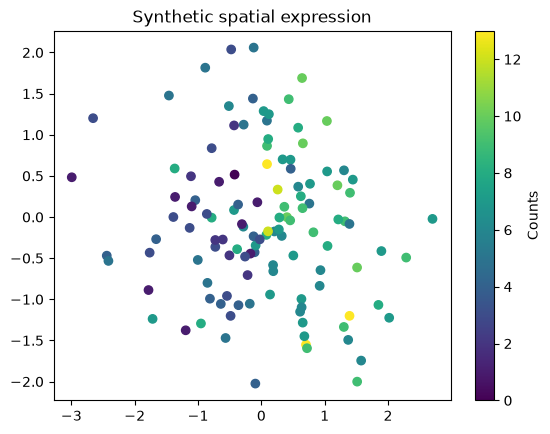

In [4]:
x=np.loadtxt(ROOT/'data/input.csv',delimiter=',')
coordinates=np.loadtxt(ROOT/'data/coordinates.csv',delimiter=',')
covariates=np.loadtxt(ROOT/'data/covariates.csv',delimiter=',')
result=sparkx(x,coordinates,covariates)
print(result['results'].head());print('ACAT example:',acat([.01,.2,.4]))
plt.scatter(coordinates[:,0],coordinates[:,1],c=x[0]);plt.colorbar(label='Counts');plt.title('Synthetic spatial expression');plt.show()


In [5]:
import subprocess
r=subprocess.run([sys.executable,'-m','pytest','-q'],cwd=ROOT,capture_output=True,text=True)
print(r.stdout)
assert r.returncode==0,r.stderr+r.stdout

....                                                                     [100%]
4 passed in 0.71s

